<a href="https://colab.research.google.com/github/songyuho1/Eco2/blob/main/P_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

데이터 형태 (샘플 수, 특성 수): (178, 13)
타겟 클래스 종류: ['class_0' 'class_1' 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



[Logistic Regression 모델 학습 및 평가]
정확도 (Accuracy): 0.9722
----------------------------------------
분류 보고서 (Classification Report):
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36


[Decision Tree 모델 학습 및 평가]
정확도 (Accuracy): 0.9444
----------------------------------------
분류 보고서 (Classification Report):
              precision    recall  f1-score   support

     class_0       1.00      0.92      0.96        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      

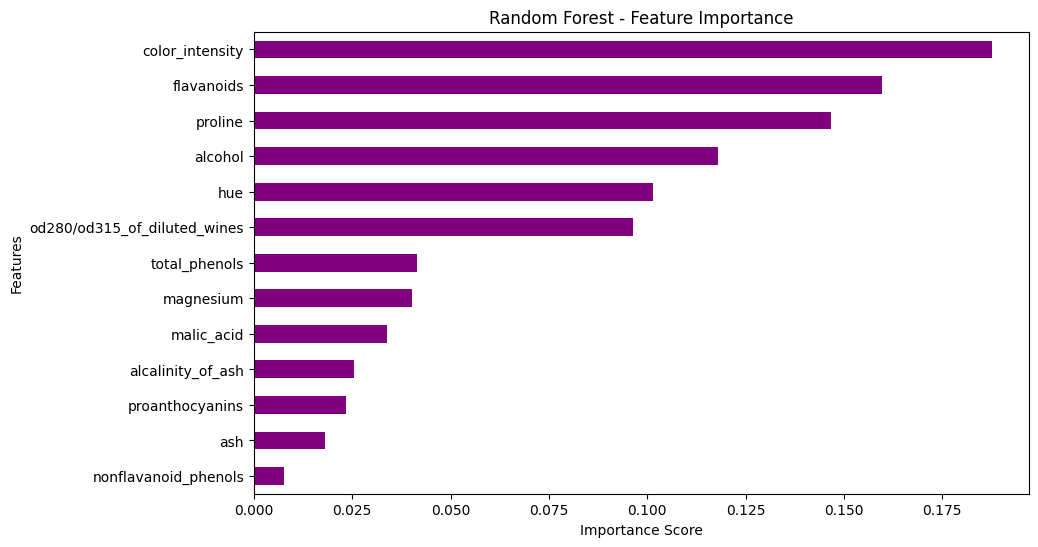

In [ ]:
# 1. 라이브러리 임포트
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 2. 데이터 로드 및 DataFrame 변환
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print(f"데이터 형태 (샘플 수, 특성 수): {X.shape}")
print(f"타겟 클래스 종류: {wine.target_names}")

# 데이터의 첫 5행 확인
display(X.head())

# 3. 학습용 / 테스트용 데이터셋 분리 (8:2 비율)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. 데이터 스케일링 (StandardScaler 적용)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. 모델 학습 및 평가 함수 정의
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

for name, model in models.items():
    print(f"\n[{name} 모델 학습 및 평가]")

    # 모델 학습 (로지스틱 회귀와 랜덤 포레스트는 스케일된 데이터 사용이 유리)
    model.fit(X_train_scaled, y_train)

    # 예측
    y_pred = model.predict(X_test_scaled)

    # 성능 지표 출력
    acc = accuracy_score(y_test, y_pred)
    print(f"정확도 (Accuracy): {acc:.4f}")
    print("-" * 40)
    print("분류 보고서 (Classification Report):")
    print(classification_report(y_test, y_pred, target_names=wine.target_names))

# 6. 가장 성능이 좋은 모델(예: Random Forest)의 피처 중요도 시각화
best_model = models["Random Forest"]
feature_importance = pd.Series(best_model.feature_importances_, index=wine.feature_names)

plt.figure(figsize=(10, 6))
feature_importance.sort_values().plot(kind='barh', color='purple')
plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 비교할 모델 3가지 준비
models = {
    "Logistic Regression (로지스틱 회귀)": LogisticRegression(random_state=42),
    "Decision Tree (결정 트리)": DecisionTreeClassifier(random_state=42),
    "Random Forest (랜덤 포레스트)": RandomForestClassifier(random_state=42)
}

# 결과를 저장할 딕셔너리
performance = {}

# 반복문을 돌며 각각 학습 및 평가 진행
for name, model in models.items():
    # 1. 모델 학습 (스케일된 훈련 데이터 사용)
    model.fit(X_train_scaled, y_train)

    # 2. 테스트 데이터로 예측 수행
    y_pred = model.predict(X_test_scaled)

    # 3. 정확도 계산
    acc = accuracy_score(y_test, y_pred)
    performance[name] = acc

    print(f"[{name}] 정확도: {acc:.4f}")

# 가장 성능이 좋은 모델 확인
best_model_name = max(performance, key=performance.get)
print(f"\n🏆 가장 뛰어난 성능을 보인 모델: {best_model_name} (정확도: {performance[best_model_name]:.4f})")

[Logistic Regression (로지스틱 회귀)] 정확도: 0.9722
[Decision Tree (결정 트리)] 정확도: 0.9444
[Random Forest (랜덤 포레스트)] 정확도: 1.0000

🏆 가장 뛰어난 성능을 보인 모델: Random Forest (랜덤 포레스트) (정확도: 1.0000)


--- [상세 분류 보고서] ---
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50752 (\N{HANGUL SYLLABLE WA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46321 (\N{HANGUL SYLLABLE DEUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/l

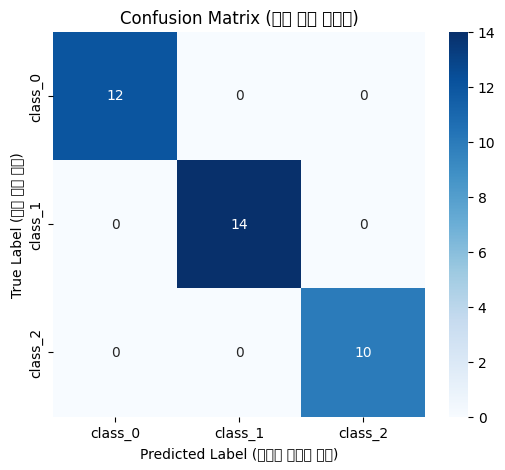

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 가장 성능이 좋았던 모델(여기서는 RandomForest 기준, 혹은 위에서 학습한 모델 활용)
best_model = models["Random Forest (랜덤 포레스트)"]
y_pred_best = best_model.predict(X_test_scaled)

# 1. 상세 분류 보고서 (정밀도, 재현율, F1-score 확인)
print("--- [상세 분류 보고서] ---")
print(classification_report(y_test, y_pred_best, target_names=wine.target_names))

# 2. 혼동 행렬(Confusion Matrix) 계산
cm = confusion_matrix(y_test, y_pred_best)

# 3. 혼동 행렬 시각화 (오답 노트)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=wine.target_names,
            yticklabels=wine.target_names)
plt.title("Confusion Matrix (오답 노트 시각화)")
plt.xlabel("Predicted Label (모델이 예측한 등급)")
plt.ylabel("True Label (실제 와인 등급)")
plt.show()

In [15]:
!cp /content/P_Project.ipynb /content/wine_project/

cp: cannot stat '/content/P_Project.ipynb': No such file or directory
